# Deliverable 2: Data Exploration and Preprocessing

**MOD10 Introduction to Machine Learning**, October 2026

- **Group:** CUPILLARD Eliot, DENOUAL Romain, ROY-NOUGUIER Erwann
- **Dataset:** Arbres publics sur le territoire de la Ville (consolidated file), City of Montreal, licence CC BY 4.0
- **Source:** https://donnees.montreal.ca/dataset/arbres
- **Copy used:** unchanged copy of `arbres-publics.csv` of 2026-10-07, https://doi.org/10.5281/zenodo.23540888
- **SHA-256:** `068031590d3e0ea126f49148fddead573541cf69b5cba1eb752ea7801eb3ca00`
- **Target (`y`):** `DHP`, the trunk diameter at 1.4 m (regression)
- **Question:** Can we predict the trunk diameter of a public tree from its species, location and age?

## 0. Setup

If the data file is missing, this cell downloads it from Zenodo. It then checks the SHA-256, so everyone works on the same file.

In [1]:
import hashlib
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_PATH = Path("../data/raw/montreal_public_trees_2026-10-07.csv")
DATA_URL = "https://zenodo.org/records/23540888/files/montreal_public_trees_2026-10-07.csv?download=1"
DATA_SHA256 = "068031590d3e0ea126f49148fddead573541cf69b5cba1eb752ea7801eb3ca00"

if not DATA_PATH.is_file():
    print("Downloading the dataset from Zenodo... (129 MB, it can take a few minutes)")
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA256, "Wrong data file: delete it and run again"

## 1. Exploration (EDA)

We look at the data before changing anything.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("DataFrame Head:")
display(df.head())
print("\nDataFrame Shape:")
print(df.shape)
print("\nDataFrame Info:")
df.info()
print("\nDataFrame Describe:")
df.describe().round(2)

DataFrame Head:


,INV_TYPE,EMP_NO,ARROND,ARROND_NOM,Rue,Rue_cote,No_civique,Emplacement,Sigle,Essence_latin,...,Stationnement_jour,Stationnement_heure,District,Arbre_remarquable,Code_secteur,Nom_secteur,Coord_X,Coord_Y,Longitude,Latitude
0,H,6,1,Ahuntsic - Cartierville,NaN,NaN,NaN,Parterre Gazonné,GLTRSK,Gleditsia triacanthos 'Skyline',...,NaN,NaN,NaN,N,2.0,SUD,287967.933,5043937.611,-73.715515,45.535151
1,H,7,1,Ahuntsic - Cartierville,NaN,NaN,NaN,Parterre Gazonné,GLTRSK,Gleditsia triacanthos 'Skyline',...,NaN,NaN,NaN,N,2.0,SUD,287961.715,5043945.204,-73.715595,45.535219
2,H,8,1,Ahuntsic - Cartierville,NaN,NaN,NaN,Parterre Gazonné,GYDI,Gymnocladus dioicus,...,NaN,NaN,NaN,N,2.0,SUD,287956.685,5043932.522,-73.715659,45.535105
3,H,9,1,Ahuntsic - Cartierville,NaN,NaN,NaN,Parterre Gazonné,FRNIFG,Fraxinus nigra 'Fall Gold',...,NaN,NaN,NaN,N,2.0,SUD,287985.011,5043989.384,-73.715298,45.535617
4,H,10,1,Ahuntsic - Cartierville,NaN,NaN,NaN,Parterre Gazonné,QURU,Quercus rubra,...,NaN,NaN,NaN,N,2.0,SUD,287961.737,5043987.310,-73.715596,45.535598



DataFrame Shape:
(335494, 33)

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 335494 entries, 0 to 335493
Data columns (total 33 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   INV_TYPE             335494 non-null  str    
 1   EMP_NO               335494 non-null  int64  
 2   ARROND               335494 non-null  int64  
 3   ARROND_NOM           335494 non-null  str    
 4   Rue                  218851 non-null  str    
 5   Rue_cote             218851 non-null  str    
 6   No_civique           171604 non-null  float64
 7   Emplacement          335494 non-null  str    
 8   Sigle                335494 non-null  str    
 9   Essence_latin        335494 non-null  str    
 10  Essence_fr           335494 non-null  str    
 11  Essence_ang          335494 non-null  str    
 12  DHP                  335354 non-null  float64
 13  Date_Releve          335354 non-null  str    
 14  Date_Plantation      201161 non

,EMP_NO,ARROND,No_civique,DHP,Distance_pave,District,Code_secteur,Coord_X,Coord_Y,Longitude,Latitude
count,335494.00,335494.00,171604.00,335354.00,194630.00,218851.00,116643.00,335494.00,335492.00,335492.00,335492.00
mean,150250.36,7.46,5318.25,25.23,2.57,317.56,4.04,296659.03,5044549.34,-73.60,45.54
std,148931.23,6.30,3679.47,22.22,1.86,156.44,15.33,13782.44,15645.00,0.15,0.14
min,1.00,1.00,0.00,0.00,0.00,100.00,1.00,262056.19,292007.68,-74.05,2.64
25%,57057.25,3.00,2215.00,5.00,1.50,183.00,1.00,294560.52,5039607.92,-73.63,45.50
50%,113980.00,6.00,5053.00,19.00,2.70,300.00,1.00,297854.01,5044635.00,-73.59,45.54
75%,189167.75,9.00,7479.00,39.00,3.20,470.00,3.00,300088.61,5048585.57,-73.56,45.58
max,797405.00,25.00,27455.00,925.00,99.99,603.00,218.00,5040614.62,5069899.71,-24.34,45.77


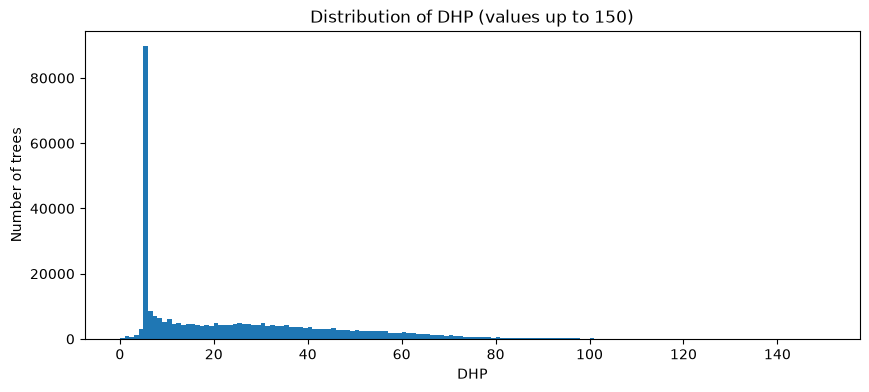

In [3]:
plt.figure(figsize=(10, 4))
plt.hist(df["DHP"], bins=np.arange(0, 151))
plt.xlabel("DHP")
plt.ylabel("Number of trees")
plt.title("Distribution of DHP (values up to 150)")
plt.show()

In [4]:
# Which DHP values are the most common?
print(df["DHP"].value_counts().head())
print(df["DHP"].value_counts(normalize=True).head().round(3))

# Suspicious values of DHP
print("DHP missing:", df["DHP"].isna().sum())
print("DHP = 0:", (df["DHP"] == 0).sum())
print("DHP > 150:", (df["DHP"] > 150).sum())
print("DHP > 250:", (df["DHP"] > 250).sum())
print("DHP max:", df["DHP"].max())
big = df[df["DHP"] > 150]
species = big["Essence_latin"].str.split().str[:2].str.join(" ")
print(species[big["DHP"] <= 250].value_counts().head(4))
display(big.loc[big["DHP"] > 250, ["Essence_latin", "DHP"]].sort_values("DHP"))
coords = df[["Latitude", "Longitude"]].dropna()
print("Coordinates far from Montreal:", (~(coords["Latitude"].between(45, 46) & coords["Longitude"].between(-75, -73))).sum())

DHP
5.0     89907
6.0      8613
7.0      7095
8.0      6321
10.0     6108
Name: count, dtype: int64
DHP
5.0     0.268
6.0     0.026
7.0     0.021
8.0     0.019
10.0    0.018
Name: proportion, dtype: float64
DHP missing: 140
DHP = 0: 383
DHP > 150: 76
DHP > 250: 13
DHP max: 925.0
Essence_latin
Populus deltoides    23
Acer saccharinum     18
Populus x            12
Populus               4
Name: count, dtype: int64


,Essence_latin,DHP
80139,Picea pungens,257.0
98387,Ostrya virginiana,259.0
125068,Celtis occidentalis,260.0
128166,Ginkgo biloba,260.0
79244,Pinus resinosa,273.0
230796,Acer saccharinum 'Pyramidalis',304.0
124651,Ulmus pumila,420.0
85458,Populus deltoides,460.0
174335,Fraxinus americana,487.0
172111,Gleditsia triacanthos var. inermis,536.0


Coordinates far from Montreal: 6


### Observations

The plot shows DHP up to 150 only (the 76 trees above 150 are left out so that the rest stays readable).

1. One value is far more common than the others: 26.8% of the trees have a DHP of exactly 5. This looks like a default or minimum value, maybe for recently planted trees (this is only our guess). We will have to decide how to treat it.
2. Most trees are small, but some values are impossible. The median DHP is 19 and 75% of the trees are below 39 (see `describe()`). However, the maximum is 925, 383 trees have a DHP of 0, and 140 trees have no DHP at all. So these rows will need a decision.

## 2. Missing values

Some columns are empty by design (they do not apply to this kind of tree), and some are missing for a reason linked to the target. We decide column by column.

In [5]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False))

print("Share of missing values by tree type:")
display(df.isna().groupby(df["INV_TYPE"]).mean().T.round(2))

Missing values per column:
NOM_PARC               218851
CODE_PARC              218851
Nom_secteur            218851
Code_secteur           218851
Stationnement_heure    202052
Distance_ligne_rue     194103
Stationnement_jour     193698
No_civique             163890
Distance_pave          140864
Date_Plantation        134333
LOCALISATION           116670
Rue_de                 116643
Localisation_code      116643
District               116643
Rue_cote               116643
Rue                    116643
Rue_a                  116643
Date_Releve               140
DHP                       140
Coord_Y                     2
Longitude                   2
Latitude                    2
EMP_NO                      0
Essence_ang                 0
Essence_fr                  0
Essence_latin               0
Arbre_remarquable           0
Sigle                       0
Emplacement                 0
Coord_X                     0
ARROND_NOM                  0
ARROND                      0
INV_TYPE     

INV_TYPE,H,R
INV_TYPE,0.00,0.00
EMP_NO,0.00,0.00
ARROND,0.00,0.00
ARROND_NOM,0.00,0.00
Rue,1.00,0.00
Rue_cote,1.00,0.00
No_civique,1.00,0.22
Emplacement,0.00,0.00
Sigle,0.00,0.00
Essence_latin,0.00,0.00


| Column(s) | Missing | Decision | Reason |
|---|---|---|---|
| `Rue`, `Rue_cote`, `Rue_de`, `Rue_a`, `LOCALISATION`, `Localisation_code`, `District` | 116,643 to 116,670 (all non-street trees) | Drop the columns | They only exist for street trees. Filling them would invent streets for park trees. |
| `No_civique`, `Distance_pave`, `Distance_ligne_rue`, `Stationnement_jour`, `Stationnement_heure` | 140,864 to 202,052 | Drop the columns | Empty for all non-street trees, and for 11% to 39% of the street trees. |
| `CODE_PARC`, `NOM_PARC`, `Code_secteur`, `Nom_secteur` | 218,851 (all street trees) | Drop the columns | They only exist for park trees, and are names or codes. |
| `Date_Plantation` | 134,333 (~40%) | Keep it as an age, fill the missing ages with the median and add a column `age_missing` | Not random: these trees are bigger (median DHP 33 against 7). Dropping them would remove most of the big trees. |
| `DHP`, `Date_Releve` | 140 each | Drop these rows | No target. This is 0.04% of the data. |
| `Latitude`, `Longitude` | 2 | Drop these rows | A tree without a position cannot be used. |
| `DHP` equal to 0 or above 250 | 396 (383 and 13) | Drop these rows | A diameter of 0 is not valid. The 13 trees above 250 look like mistakes (up to 925, see the list above). We keep the trees from 150 to 250: most of them are poplars and silver maples. |
| `Latitude`, `Longitude` far from Montreal | 6 | Drop these rows | Impossible values. We keep a box of 1 degree around Montreal. |

**Notes on the age**

- The age is the year of the last measurement minus the year of planting. Negative ages and ages above 100 are treated as unknown. The ages above 100 look like mistakes: most are in one borough (Saint-Léonard) and they share very few planting dates.
- Unknown ages get the median of the known ages (3), not the mean (11.4), because a few old trees pull the mean up.
- `age_missing` marks the filled ages. These trees are bigger (median DHP 33 against 7), so without it the model would take them for young trees.
- Limit: with 40% of the ages filled by one value, the link between age and DHP is hidden (correlation 0.84 on the known ages, 0.39 after filling). The median is also computed before the split. It is one number, so the effect is very small.

In [6]:
# 1. Drop the columns that are empty by design
columns_to_drop = [
    "Rue", "Rue_cote", "Rue_de", "Rue_a", "LOCALISATION", "Localisation_code", "District",
    "No_civique", "Distance_pave", "Distance_ligne_rue", "Stationnement_jour", "Stationnement_heure",
    "CODE_PARC", "NOM_PARC", "Code_secteur", "Nom_secteur",
]
df_clean = df.drop(columns=columns_to_drop)

# 2. Drop the rows without target or position, with an impossible DHP, or far from Montreal
df_clean = df_clean.dropna(subset=["DHP", "Date_Releve", "Latitude", "Longitude"])
df_clean = df_clean[(df_clean["DHP"] > 0) & (df_clean["DHP"] <= 250)]
df_clean = df_clean[df_clean["Latitude"].between(45, 46) & df_clean["Longitude"].between(-75, -73)]

# 3. Age of the tree at its last measurement (difference of the two years)
survey_year = df_clean["Date_Releve"].str[:4].astype(float)
planting_year = df_clean["Date_Plantation"].str[:4].astype(float)
df_clean["age"] = survey_year - planting_year

too_old = df_clean[df_clean["age"] > 100]
print("<0 ages:", (df_clean["age"] < 0).sum(), "| >100:", len(too_old))
print("Ages > 100, by borough:", too_old["ARROND_NOM"].value_counts().head(2).to_dict())
print("Ages > 100, different planting dates:", too_old["Date_Plantation"].nunique())

# 4. Impossible ages (<0 or >100) are treated as unknown
df_clean.loc[(df_clean["age"] < 0) | (df_clean["age"] > 100), "age"] = np.nan

# 5. Mark the unknown ages, then fill them with the median
df_clean["age_missing"] = df_clean["age"].isna().astype(int)
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

# 6. The raw dates are not needed anymore
df_clean = df_clean.drop(columns=["Date_Plantation", "Date_Releve"])

<0 ages: 71 | >100: 123
Ages > 100, by borough: {'Saint-Léonard': 111, 'Mercier - Hochelaga-Maisonneuve': 5}
Ages > 100, different planting dates: 19


In [7]:
print("Rows before:", len(df), "| after:", len(df_clean))
print("Columns before:", df.shape[1], "| after:", df_clean.shape[1])
print("Missing values left:", df_clean.isna().sum().sum())
print("Trees with unknown age:", df_clean["age_missing"].sum())
print(df_clean["age"].describe().round(1))

Rows before: 335494 | after: 334950
Columns before: 33 | after: 17
Missing values left: 0
Trees with unknown age: 134148
count    334950.0
mean          8.1
std          13.3
min           0.0
25%           0.0
50%           3.0
75%           6.0
max          97.0
Name: age, dtype: float64


In [8]:
known = df_clean[df_clean["age_missing"] == 0]
unknown = df_clean[df_clean["age_missing"] == 1]

print("Known ages, mean and median:", round(known["age"].mean(), 1), known["age"].median())
print("Median DHP, known ages and unknown ages:", known["DHP"].median(), unknown["DHP"].median())
print("Correlation age/DHP, known ages and all trees after filling:", round(known["age"].corr(known["DHP"]), 2), round(df_clean["age"].corr(df_clean["DHP"]), 2))

Known ages, mean and median: 11.4 3.0
Median DHP, known ages and unknown ages: 7.0 33.0
Correlation age/DHP, known ages and all trees after filling: 0.84 0.39


## 3. Encoding

- `INV_TYPE` and `Arbre_remarquable` have two values: `map()` to 0 and 1.
- `ARROND_NOM`, `Emplacement` and `Essence_latin` have no order: `get_dummies()`.
- `Latitude`, `Longitude`, `age` and `age_missing` are already numbers.

We do not use `EMP_NO` (an identifier), `ARROND` (same as `ARROND_NOM`), `Sigle`, `Essence_fr` and `Essence_ang` (a code or a translation of `Essence_latin`), `Coord_X` and `Coord_Y` (same position as `Latitude` and `Longitude`).

To avoid too many columns, we group the rare categories in "Other". We keep the species name (the first two words of `Essence_latin`) in lower case, because a few species are written in two ways (for example `Ulmus x` and `Ulmus X`). We keep the 30 most common species and the 10 most common places.

In [9]:
y = df_clean["DHP"]
X = df_clean.drop(columns=["DHP", "EMP_NO", "ARROND", "Sigle", "Essence_fr", "Essence_ang", "Coord_X", "Coord_Y"])

X["INV_TYPE"] = X["INV_TYPE"].map({"H": 0, "R": 1})
X["Arbre_remarquable"] = X["Arbre_remarquable"].map({"N": 0, "O": 1})

In [10]:
print("Different names:", X["Essence_latin"].nunique())
X["Essence_latin"] = X["Essence_latin"].str.split().str[:2].str.join(" ").str.lower()
print("Different species:", X["Essence_latin"].nunique())

top_species = X["Essence_latin"].value_counts().head(30).index
top_places = X["Emplacement"].value_counts().head(10).index
print(f"Trees in the 30 most common species: {X['Essence_latin'].isin(top_species).mean():.1%}")
print(f"Trees in the 10 most common places: {X['Emplacement'].isin(top_places).mean():.1%}")

X["Essence_latin"] = X["Essence_latin"].where(X["Essence_latin"].isin(top_species), "Other")
X["Emplacement"] = X["Emplacement"].where(X["Emplacement"].isin(top_places), "Other")

Different names: 806
Different species: 339
Trees in the 30 most common species: 80.8%
Trees in the 10 most common places: 96.3%


In [11]:
X = pd.get_dummies(X, columns=["ARROND_NOM", "Emplacement", "Essence_latin"], dtype=int)

In [12]:
print("X:", X.shape, "| y:", y.shape)
print("Columns that are not numbers:", list(X.select_dtypes(exclude="number").columns))
print("Missing values:", X.isna().sum().sum())

X: (334950, 61) | y: (334950,)
Columns that are not numbers: []
Missing values: 0


**Optional:** save the encoded data in `data/processed/` for our own use (the first column is the row number in the raw file). The notebook does not need this file.

In [13]:
output_path = Path("../data/processed/trees_encoded.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
#pd.concat([X, y], axis=1).to_csv(output_path, index_label="raw_row")

## 4. Train/test split

20% of the trees go to the test set, with `random_state=SEED` for a fixed split. There is no `stratify` because our `y` is a number. We split before scaling, so the scaler never sees the test data.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (267960, 61)
Test: (66990, 61)


## 5. Scaling

`Latitude`, `Longitude` and `age` have very different scales (see the standard deviations below), which matters for a distance-based model like KNN. We standardize these three columns only, because the other columns are 0/1. The scaler is fitted on `X_train` only and then applied to `X_test`, to avoid data leakage. `y` is not scaled.

In [15]:
columns_to_scale = ["Latitude", "Longitude", "age"]
print("Standard deviation before scaling:")
print(X_train[columns_to_scale].std().round(3))

scaler = StandardScaler()
# fit on the training set only
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

Standard deviation before scaling:
Latitude      0.059
Longitude     0.076
age          13.313
dtype: float64


In [16]:
print("Shapes:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("Missing values:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("Columns that are not numbers:", list(X_train.select_dtypes(exclude="number").columns))

print("Standard deviation after scaling:")
display(X_train[columns_to_scale].agg(["mean", "std"]).round(3))
display(X_test[columns_to_scale].agg(["mean", "std"]).round(3))

Shapes: (267960, 61) (66990, 61) (267960,) (66990,)
Missing values: 0 0
Columns that are not numbers: []
Standard deviation after scaling:


,Latitude,Longitude,age
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0


,Latitude,Longitude,age
mean,0.003,0.003,-0.004
std,0.998,0.998,0.994


## 6. Reflection

**Main decisions**

- Trees with an unknown age are kept and marked with `age_missing`, instead of dropping 40% of the trees (mostly big ones).
- Columns empty by design are dropped, and so are the rows with an impossible DHP (=0 or >250) or impossible coordinates. Trees from 150 to 250 are kept: they look like real big trees.
- Rare species and places are grouped in "Other".
- We split before scaling, and the scaler is fitted on the training set only.

**What surprised us**

- 27% of the trees have a DHP of exactly 5, probably a default value. We kept them.
- The trees without a planting date are the biggest ones, so filling their age with the median hides the link between age and DHP.